# Análisis exploratorio

Solo se usa **train**: val y test no se miran hasta la evaluación final, para que ninguna decisión dependa de ellos.

Requiere `make data` y `make prepare`.

In [1]:
import pandas as pd

from oil_rnn.config import get, load_config
from oil_rnn.data import load_split

cfg = load_config()
train = load_split("train")
train.shape

(4454, 22)

In [2]:
train.head()

,date,brent,wti,henry_hub,ecb_deposit_rate,usd_per_eur,cny_per_usd,vix,brent_fut_open,brent_fut_high,...,brent_fut_volume,wti_fut_open,wti_fut_high,wti_fut_low,wti_fut_close,wti_fut_volume,copper,gold,dollar_index,_context
0,2000-08-30,34.13,33.25,4.53,3.25,0.8924,8.2788,17.69,NaN,NaN,...,NaN,32.750000,33.400002,32.099998,33.400002,79214.0,0.8850,273.899994,112.139999,False
1,2000-09-01,35.09,33.42,4.53,3.50,0.8993,8.2787,17.53,NaN,NaN,...,NaN,33.049999,33.450001,32.750000,33.380001,45869.0,0.8890,277.000000,111.419998,False
2,2000-09-04,36.02,33.42,4.53,3.50,0.8993,8.2787,17.53,NaN,NaN,...,NaN,33.049999,33.450001,32.750000,33.380001,45869.0,0.8890,277.000000,111.419998,False
3,2000-09-05,35.72,33.92,4.53,3.50,0.8876,8.2790,19.82,NaN,NaN,...,NaN,33.950001,33.990002,33.419998,33.799999,55722.0,0.9060,275.799988,112.410004,False
4,2000-09-06,36.70,34.97,4.53,3.50,0.8702,8.2794,20.79,NaN,NaN,...,NaN,33.990002,34.950001,33.830002,34.950001,74692.0,0.9015,274.200012,114.120003,False


In [3]:
train.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,4454,NaN,NaN,NaN,2010-05-19 03:52:27.373147,2000-08-30 00:00:00,2005-12-16 18:00:00,2010-06-29 12:00:00,2014-12-04 18:00:00,2019-04-22 00:00:00,NaN
brent,4454.0,NaN,NaN,NaN,67.644818,16.51,45.055,63.555,93.2,143.95,29.809465
wti,4454.0,NaN,NaN,NaN,64.624881,17.5,45.1625,61.66,86.695,145.31,26.011595
henry_hub,4454.0,NaN,NaN,NaN,4.665745,1.49,3.0,4.01,5.77,18.48,2.271627
ecb_deposit_rate,4454.0,NaN,NaN,NaN,0.863931,-0.4,-0.2,0.25,1.75,3.75,1.250023
usd_per_eur,4454.0,NaN,NaN,NaN,1.230893,0.827,1.129225,1.24875,1.3436,1.601,0.159196
cny_per_usd,4454.0,NaN,NaN,NaN,7.108439,6.0402,6.383325,6.82875,8.075925,8.28,0.803096
vix,4454.0,NaN,NaN,NaN,19.35412,9.14,13.36,16.91,22.6375,80.86,8.710041
brent_fut_open,2962.0,NaN,NaN,NaN,81.052498,27.950001,57.0275,77.440002,107.629999,146.080002,26.087353
brent_fut_high,2962.0,NaN,NaN,NaN,81.900652,28.969999,57.905001,78.259998,108.32,147.429993,26.149953


## Valores vacíos por columna

In [4]:
train.isna().sum().loc[lambda s: s > 0]

brent_fut_open      1492
brent_fut_high      1492
brent_fut_low       1492
brent_fut_close     1492
brent_fut_volume    1492
dtype: int64

## Variable objetivo

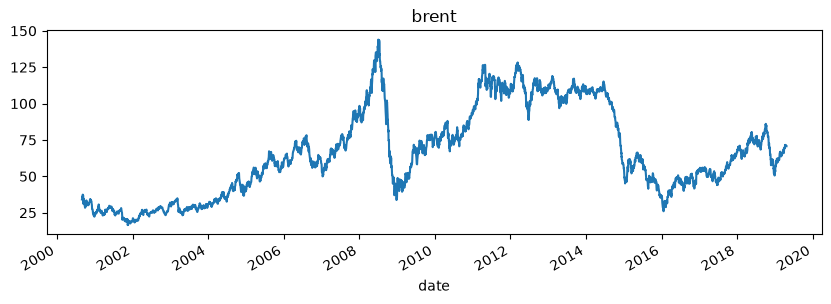

In [5]:
target = get(cfg, "data.target")
time_col = get(cfg, "data.time_column")
if target == "PENDIENTE":
    print("data.target sigue PENDIENTE en configs/config.yaml")
elif time_col not in (None, "PENDIENTE"):
    train.plot(x=time_col, y=target, figsize=(10, 3), legend=False, title=target)
elif pd.api.types.is_numeric_dtype(train[target]):
    train[target].plot.hist(bins=30, title=target)
else:
    train[target].value_counts().plot.bar(title=target)

## Primera fecha con dato de cada columna

Los vacíos del inicio no se pueden rellenar con valores pasados. Una columna que empieza tarde obliga a quitarla de `data.features` o a recortar el comienzo de la serie.

In [6]:
import numpy as np

t = train.set_index(time_col)
numeric = t.select_dtypes("number")
pd.DataFrame(
    {
        "primera_fecha": numeric.apply(lambda s: s.first_valid_index()),
        "vacios": numeric.isna().sum(),
        "pct_vacios": (numeric.isna().mean() * 100).round(1),
    }
).sort_values("primera_fecha")

,primera_fecha,vacios,pct_vacios
brent,2000-08-30,0,0.0
copper,2000-08-30,0,0.0
wti_fut_volume,2000-08-30,0,0.0
wti_fut_close,2000-08-30,0,0.0
wti_fut_low,2000-08-30,0,0.0
wti_fut_high,2000-08-30,0,0.0
wti_fut_open,2000-08-30,0,0.0
gold,2000-08-30,0,0.0
dollar_index,2000-08-30,0,0.0
vix,2000-08-30,0,0.0


## Valores no positivos

El rendimiento logarítmico exige precios positivos. El WTI cotizó en negativo el 20/04/2020; aquí se comprueba si ese día cae en train y si alguna otra columna tiene valores ≤ 0.

In [7]:
non_positive = (numeric <= 0).sum()
has_any = (non_positive > 0).any()
print(non_positive[non_positive > 0] if has_any else "Ninguna columna con valores <= 0")
print("Fin de train:", t.index.max().date())

ecb_deposit_rate    1722
brent_fut_volume       6
wti_fut_volume         5
dtype: int64
Fin de train: 2019-04-22


## Nivel frente a rendimiento

Una serie estacionaria mantiene media y varianza a lo largo del tiempo. Se compara el precio con su rendimiento logarítmico diario: autocorrelación a 1 día y media por tramos de cuatro años.

In [8]:
price = t[target]
ret1 = np.log(price).diff().dropna()
print(f"Autocorrelación a 1 día · nivel: {price.autocorr(1):.3f}")
print(f"Autocorrelación a 1 día · rendimiento: {ret1.autocorr(1):.3f}")
by_period = pd.DataFrame(
    {
        "precio_medio": price.groupby(price.index.year // 4 * 4).mean(),
        "rendimiento_medio_diario": ret1.groupby(ret1.index.year // 4 * 4).mean(),
        "volatilidad_diaria": ret1.groupby(ret1.index.year // 4 * 4).std(),
    }
).round(4)
by_period

Autocorrelación a 1 día · nivel: 0.999
Autocorrelación a 1 día · rendimiento: 0.009


,precio_medio,rendimiento_medio_diario,volatilidad_diaria
date,,,
2000,26.8070,-0.0002,0.0292
2004,58.1641,0.0012,0.0208
2008,87.3037,0.0001,0.0259
2012,92.6953,-0.0011,0.0168
2016,57.0675,0.0008,0.0216


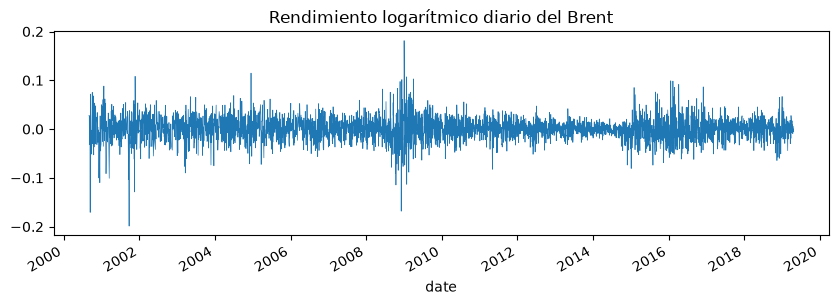

In [9]:
title = "Rendimiento logarítmico diario del Brent"
ax = ret1.plot(figsize=(10, 3), linewidth=0.5, title=title)

## Rendimiento a cada horizonte

Para cada horizonte h: dispersión del rendimiento a h días y sus cuantiles 10, 50 y 90. Esos cuantiles son la referencia trivial del intervalo del 80 %. La autocorrelación se calcula con rendimientos no solapados (uno cada h días): si es cercana a cero, el rendimiento pasado no anticipa el siguiente y la persistencia es difícil de superar.

In [10]:
rows = []
for h in (5, 21, 63, 252):
    r = np.log(price).diff(h).dropna()
    independent = r.iloc[::h]
    rows.append(
        {
            "horizonte": h,
            "desv_tipica": r.std(),
            "q10": r.quantile(0.1),
            "q50": r.quantile(0.5),
            "q90": r.quantile(0.9),
            "n_no_solapados": len(independent),
            "autocorr_no_solapada": independent.autocorr(1),
        }
    )
pd.DataFrame(rows).set_index("horizonte").round(3)

,desv_tipica,q10,q50,q90,n_no_solapados,autocorr_no_solapada
horizonte,,,,,,
5,0.052,-0.064,0.004,0.060,890,-0.029
21,0.108,-0.134,0.015,0.127,212,0.009
63,0.197,-0.235,0.032,0.220,70,0.027
252,0.357,-0.547,0.085,0.476,17,-0.061


## Volatilidad por régimen

Desviación típica móvil de 21 días del rendimiento diario, anualizada. Los tramos de volatilidad alta son los que más pesan en el error.

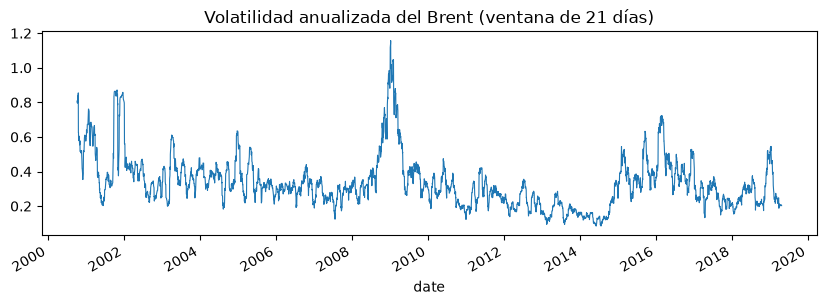

In [11]:
vol = ret1.rolling(21).std() * np.sqrt(252)
title = "Volatilidad anualizada del Brent (ventana de 21 días)"
ax = vol.plot(figsize=(10, 3), linewidth=0.8, title=title)

## Relación de cada variable con el rendimiento futuro del Brent

Correlación entre el rendimiento de cada variable en los últimos 21 días y el rendimiento del Brent en los h días siguientes. Las ventanas se solapan, así que estos valores orientan la elección de `data.features` pero no son un contraste estadístico. El tipo del BCE y los volúmenes se usan en diferencias, no en logaritmos.

In [12]:
prices = [c for c in numeric.columns if not c.endswith("_volume")]
positive = [c for c in prices if (numeric[c].dropna() > 0).all()]
past = np.log(numeric[positive]).diff(21)
table = {}
for h in (5, 21, 63, 252):
    future = np.log(price).shift(-h) - np.log(price)
    table[h] = past.corrwith(future)
pd.DataFrame(table).round(3).sort_values(5, key=abs, ascending=False)

,5,21,63,252
brent_fut_close,0.098,0.212,0.153,-0.038
copper,0.091,0.179,0.244,0.086
brent_fut_high,0.087,0.212,0.151,-0.043
vix,-0.087,-0.155,-0.131,-0.052
brent_fut_low,0.085,0.208,0.147,-0.039
brent_fut_open,0.078,0.205,0.144,-0.043
cny_per_usd,-0.063,-0.075,-0.033,0.113
dollar_index,-0.061,-0.096,-0.150,-0.090
usd_per_eur,0.059,0.077,0.141,0.076
wti_fut_close,0.040,0.060,0.038,-0.041
